# Customer Churn Prediction: Model Training, Tuning and Evaluation
**Course:** Data Mining & Knowledge Discovery (505043) - TDTU
**Phase:** Final - Classification (Modeling Lead) plus feature importance and business interpretation (Business Analyst)
**Input:** `dataset/churn_train.csv` and `dataset/churn_test.csv` from `churn_features.ipynb`

**Pipeline in this notebook**
1. Preprocessing and SMOTE inside one leak-free pipeline
2. Baselines versus four tuned models (Logistic Regression, Decision Tree, Random Forest, XGBoost) with `GridSearchCV`
3. Test-set evaluation: Confusion Matrix, Precision, Recall, F1-Score, ROC-AUC
4. SMOTE ablation (with versus without)
5. Feature importance ranking
6. Churn risk tiers and business interpretation

## 1. Setup and data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid", context="notebook")
RS = 42
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

train = pd.read_csv("dataset/churn_train.csv")
test = pd.read_csv("dataset/churn_test.csv")
FEATURES = [c for c in train.columns if c not in ("CustomerID", "Churn")]
X_train, y_train = train[FEATURES], train["Churn"]
X_test, y_test = test[FEATURES], test["Churn"]
print(f"Train {X_train.shape} | Test {X_test.shape} | churn rate train {y_train.mean():.1%}, test {y_test.mean():.1%}")

Train (4224, 13) | Test (1057, 13) | churn rate train 56.6%, test 56.6%


## 2. Leak-free pipeline
Every model runs inside the same pipeline: `log1p` (reduces skew) -> `StandardScaler` -> `SMOTE` -> classifier. Because SMOTE is a pipeline step, `GridSearchCV` applies it **only to the training folds** of each split. The validation fold and the test set are never oversampled.

In [2]:
def make_pipe(estimator, smote=True):
    steps = [("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]
    if smote:
        steps.append(("smote", SMOTE(random_state=RS)))
    steps.append(("model", estimator))
    return ImbPipeline(steps)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RS),
    "Decision Tree":       DecisionTreeClassifier(random_state=RS),
    "Random Forest":       RandomForestClassifier(random_state=RS, n_jobs=1),
    "XGBoost":             XGBClassifier(random_state=RS, eval_metric="logloss", n_jobs=1, tree_method="hist"),
}

GRIDS = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Decision Tree":       {"model__max_depth": [3, 5, 8, 12], "model__min_samples_leaf": [5, 20, 50], "model__criterion": ["gini", "entropy"]},
    "Random Forest":       {"model__n_estimators": [200, 400], "model__max_depth": [8, 12, None], "model__min_samples_leaf": [3, 10]},
    "XGBoost":             {"model__n_estimators": [200, 400], "model__max_depth": [3, 5], "model__learning_rate": [0.05, 0.1]},
}
print({k: int(np.prod([len(v) for v in g.values()])) for k, g in GRIDS.items()}, "parameter combinations (x5 folds)")

{'Logistic Regression': 4, 'Decision Tree': 24, 'Random Forest': 12, 'XGBoost': 8} parameter combinations (x5 folds)


## 3. Baselines

In [3]:
def cv_auc(pipe):
    return cross_val_score(pipe, X_train, y_train, cv=CV, scoring="roc_auc").mean()

base = {"Majority-class dummy": roc_auc_score(y_train, np.full(len(y_train), 0.5))}
for name, est in MODELS.items():
    base[f"{name} (default)"] = cv_auc(make_pipe(clone(est)))
baseline = pd.Series(base, name="CV ROC-AUC").round(4).to_frame()
baseline

,CV ROC-AUC
Majority-class dummy,0.5000
Logistic Regression (default),0.7909
Decision Tree (default),0.6314
Random Forest (default),0.7812
XGBoost (default),0.7630


## 4. Hyperparameter tuning with GridSearchCV
Scoring uses **ROC-AUC** (threshold-free and robust to class balance), with 5-fold stratified cross-validation on the training set only.

In [4]:
tuned, rows = {}, []
for name, est in MODELS.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clone(est)), GRIDS[name], scoring="roc_auc", cv=CV, n_jobs=1, refit=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    rows.append({"Model": name, "Best CV ROC-AUC": gs.best_score_, "Fit time (s)": time.time() - t0,
                 "Best parameters": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
    print(f"{name:20s} CV AUC = {gs.best_score_:.4f} | {time.time() - t0:5.0f}s | {rows[-1]['Best parameters']}")
tuning = pd.DataFrame(rows).set_index("Model")

Logistic Regression  CV AUC = 0.7911 |     1s | {'C': 10}


Decision Tree        CV AUC = 0.7778 |     7s | {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20}


Random Forest        CV AUC = 0.7972 |   107s | {'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 400}


XGBoost              CV AUC = 0.7927 |    12s | {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}


## 5. Test-set evaluation

In [5]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred), "Recall": recall_score(y, pred),
            "F1-Score": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba)}, proba, pred

results, probas, preds = {}, {}, {}
for name, gs in tuned.items():
    results[name], probas[name], preds[name] = evaluate(gs.best_estimator_, X_test, y_test)

comparison = pd.DataFrame(results).T
comparison.insert(0, "CV ROC-AUC", tuning["Best CV ROC-AUC"])
comparison = comparison.sort_values("ROC-AUC", ascending=False)
comparison.round(4)

,CV ROC-AUC,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
XGBoost,0.7927,0.7512,0.7944,0.7559,0.7746,0.8150,0.8339
Random Forest,0.7972,0.7550,0.7888,0.7742,0.7814,0.8146,0.8295
Logistic Regression,0.7911,0.7446,0.7971,0.7358,0.7652,0.8109,0.8298
Decision Tree,0.7778,0.7200,0.8120,0.6572,0.7264,0.8066,0.8077


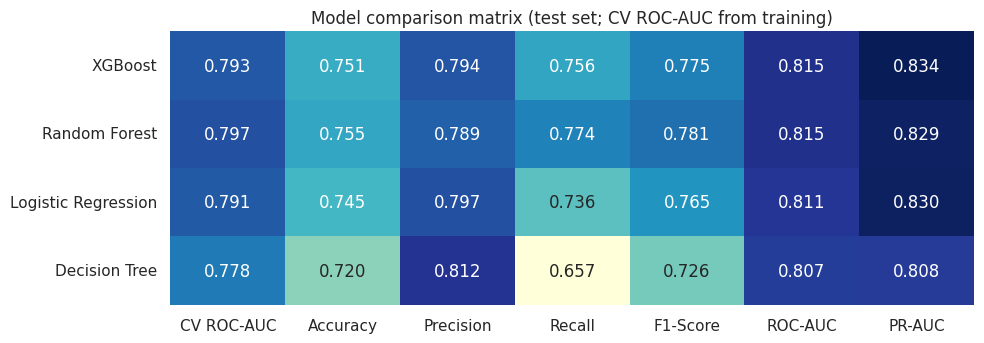

In [6]:
# Model comparison matrix (heatmap) - colour is scaled per column
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(comparison, annot=True, fmt=".3f", cmap="YlGnBu", cbar=False, ax=ax)
ax.set_title("Model comparison matrix (test set; CV ROC-AUC from training)")
plt.tight_layout(); fig.savefig(OUT / "model_comparison.png", dpi=150); plt.show()
comparison.round(4).to_csv(OUT / "model_comparison.csv")

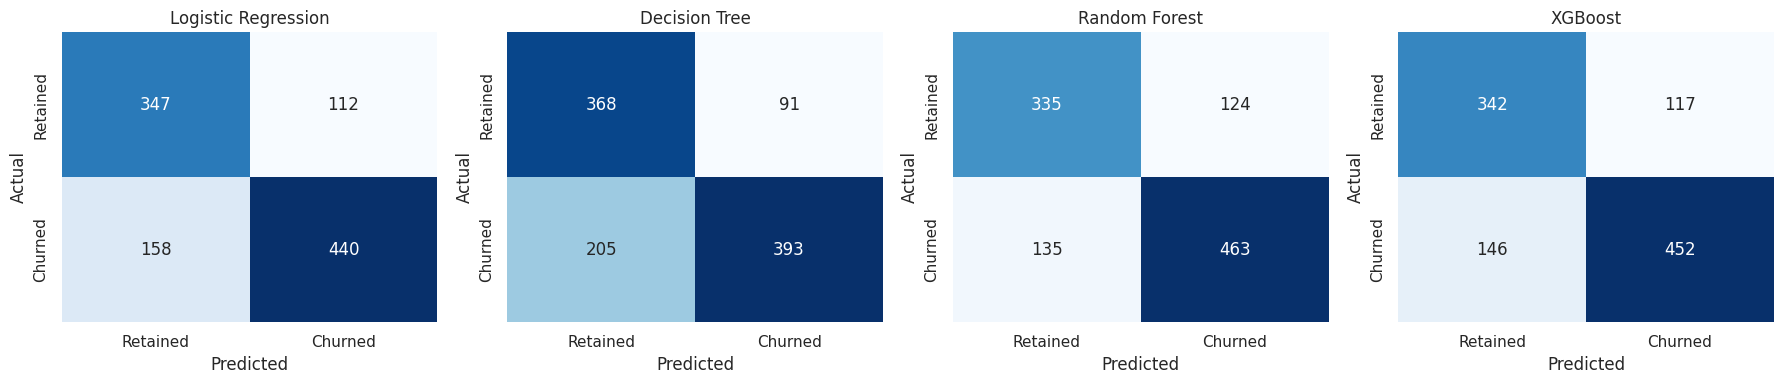

In [7]:
# Confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); fig.savefig(OUT / "confusion_matrices.png", dpi=150); plt.show()

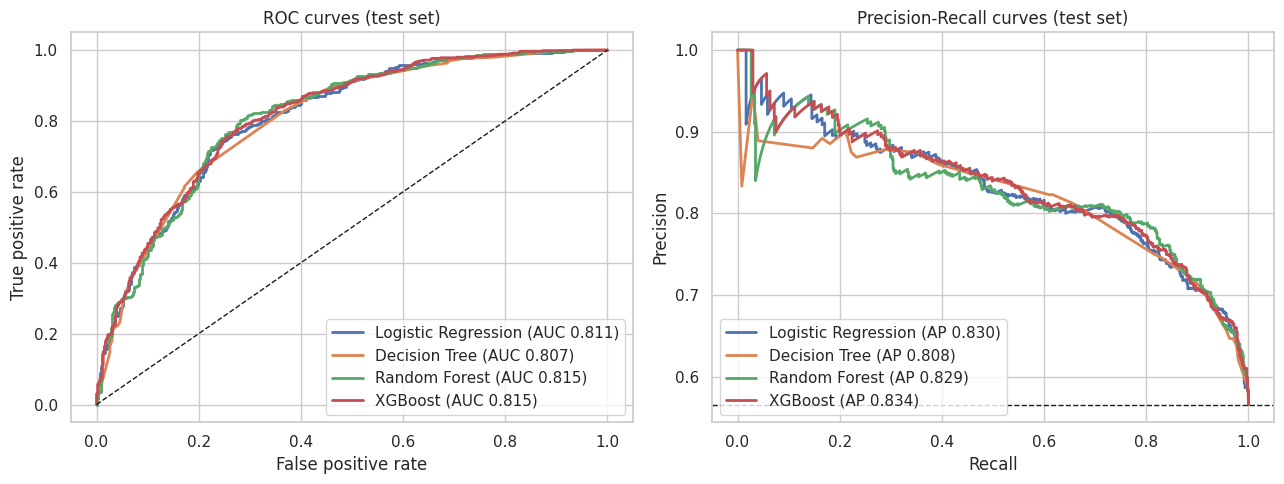

In [8]:
# ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, probas[name]); axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {results[name]['ROC-AUC']:.3f})")
    p, r, _ = precision_recall_curve(y_test, probas[name]); axes[1].plot(r, p, lw=2, label=f"{name} (AP {results[name]['PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curves (test set)"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set_title("Precision-Recall curves (test set)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "lower left")
plt.tight_layout(); fig.savefig(OUT / "roc_pr_curves.png", dpi=150); plt.show()

In [9]:
# Detailed per-class report for the best model by cross-validated AUC (chosen without looking at the test set)
from sklearn.metrics import classification_report
BEST = tuning["Best CV ROC-AUC"].idxmax()
print("Best model by CV ROC-AUC:", BEST)
print(classification_report(y_test, preds[BEST], target_names=["Retained", "Churned"], digits=3))

Best model by CV ROC-AUC: Random Forest
              precision    recall  f1-score   support

    Retained      0.713     0.730     0.721       459
     Churned      0.789     0.774     0.781       598

    accuracy                          0.755      1057
   macro avg      0.751     0.752     0.751      1057
weighted avg      0.756     0.755     0.755      1057



**How to read the metrics**
- **Precision:** of the customers flagged as churners, how many really churn (cost of wasted offers).
- **Recall:** of the customers who really churn, how many are caught (cost of missed customers).
- **F1-Score:** the balance of the two. **ROC-AUC:** how well the model ranks churners above non-churners, regardless of threshold.

## 6. SMOTE ablation: with versus without

In [10]:
abl = []
for name, est in MODELS.items():
    params = {k: v for k, v in tuned[name].best_params_.items()}
    for use_smote in (True, False):
        pipe = make_pipe(clone(est), smote=use_smote).set_params(**params).fit(X_train, y_train)
        m, _, _ = evaluate(pipe, X_test, y_test)
        abl.append({"Model": name, "SMOTE": "with" if use_smote else "without", **m})
ablation = pd.DataFrame(abl).set_index(["Model", "SMOTE"])
ablation.round(4)

Accuracy  Precision  Recall  F1-Score  ROC-AUC  \
Model               SMOTE                                                     
Logistic Regression with       0.7446     0.7971  0.7358    0.7652   0.8109   
                    without    0.7455     0.7543  0.8161    0.7839   0.8111   
Decision Tree       with       0.7200     0.8120  0.6572    0.7264   0.8066   
                    without    0.7578     0.7723  0.8110    0.7912   0.8058   
Random Forest       with       0.7550     0.7888  0.7742    0.7814   0.8146   
                    without    0.7625     0.7601  0.8478    0.8016   0.8168   
XGBoost             with       0.7512     0.7944  0.7559    0.7746   0.8150   
                    without    0.7465     0.7477  0.8328    0.7880   0.8152   

                             PR-AUC  
Model               SMOTE            
Logistic Regression with     0.8298  
                    without  0.8295  
Decision Tree       with     0.8077  
                    without  0.8085  
Random Forest       with     0.8295  
                    without  0.8309  
XGBoost             with     0.8339  
                    without  0.8298

**Interpretation.** The churn rate is only mildly imbalanced, so SMOTE is not expected to change ROC-AUC much; it mainly shifts the balance between Precision and Recall. We keep it in the pipeline because the project requires class-imbalance handling, and we report the ablation so that the choice is evidence-based.

## 7. Choosing a decision threshold

In [11]:
best_model = tuned[BEST].best_estimator_
rows = []
for th in (0.3, 0.4, 0.5, 0.6, 0.7):
    m, _, _ = evaluate(best_model, X_test, y_test, threshold=th)
    rows.append({"Threshold": th, "Precision": m["Precision"], "Recall": m["Recall"], "F1-Score": m["F1-Score"]})
pd.DataFrame(rows).set_index("Threshold").round(3)

,Precision,Recall,F1-Score
Threshold,,,
0.3,0.680,0.940,0.789
0.4,0.741,0.860,0.796
0.5,0.789,0.774,0.781
0.6,0.807,0.635,0.711
0.7,0.849,0.431,0.572


A **lower threshold** catches more churners (higher recall) but contacts more customers who would have stayed. A **higher threshold** targets fewer, more certain customers. The right setting depends on the cost of the retention offer versus the value of the customer (section 9).

## 8. Feature importance
Five complementary views are used, because impurity-based importance can favor continuous features:
1. Decision Tree impurity importance  2. Random Forest impurity importance  3. XGBoost gain importance
4. Logistic Regression standardized coefficients  5. **Permutation importance** on the test set (model-agnostic, scored by ROC-AUC drop)

In [12]:
imp = pd.DataFrame(index=FEATURES)
imp["Decision Tree"] = tuned["Decision Tree"].best_estimator_.named_steps["model"].feature_importances_
imp["Random Forest"] = tuned["Random Forest"].best_estimator_.named_steps["model"].feature_importances_
imp["XGBoost (gain)"] = tuned["XGBoost"].best_estimator_.named_steps["model"].feature_importances_

perm = permutation_importance(tuned["Random Forest"].best_estimator_, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RS, n_jobs=1)
imp["RF permutation (AUC drop)"] = perm.importances_mean
coef = pd.Series(tuned["Logistic Regression"].best_estimator_.named_steps["model"].coef_[0], index=FEATURES, name="LR coefficient")

rank = imp.rank(ascending=False)
imp["Mean rank (4 tree-based views)"] = rank.mean(axis=1)
imp_sorted = imp.sort_values("Mean rank (4 tree-based views)")
display(imp_sorted.round(4))
imp_sorted.round(5).to_csv(OUT / "feature_importance.csv")

,Decision Tree,Random Forest,XGBoost (gain),RF permutation (AUC drop),Mean rank (4 tree-based views)
Recency,0.6142,0.2223,0.2896,0.0384,1.00
Frequency,0.1944,0.1229,0.1628,0.0095,2.25
AvgDaysBetweenOrders,0.0836,0.1049,0.0585,0.0148,4.25
Monetary,0.0199,0.1083,0.0664,0.0053,5.00
UniqueProducts,0.0125,0.0856,0.0801,0.0053,5.00
Spend_Last90d,0.0068,0.1130,0.1247,0.0031,5.25
AvgBasketValue,0.0473,0.0437,0.0263,-0.0000,8.25
ItemDiversity,0.0097,0.0352,0.0264,0.0002,8.50
Orders_Last90d,0.0000,0.0630,0.0747,-0.0000,8.50
Tenure,0.0040,0.0422,0.0271,0.0000,9.00


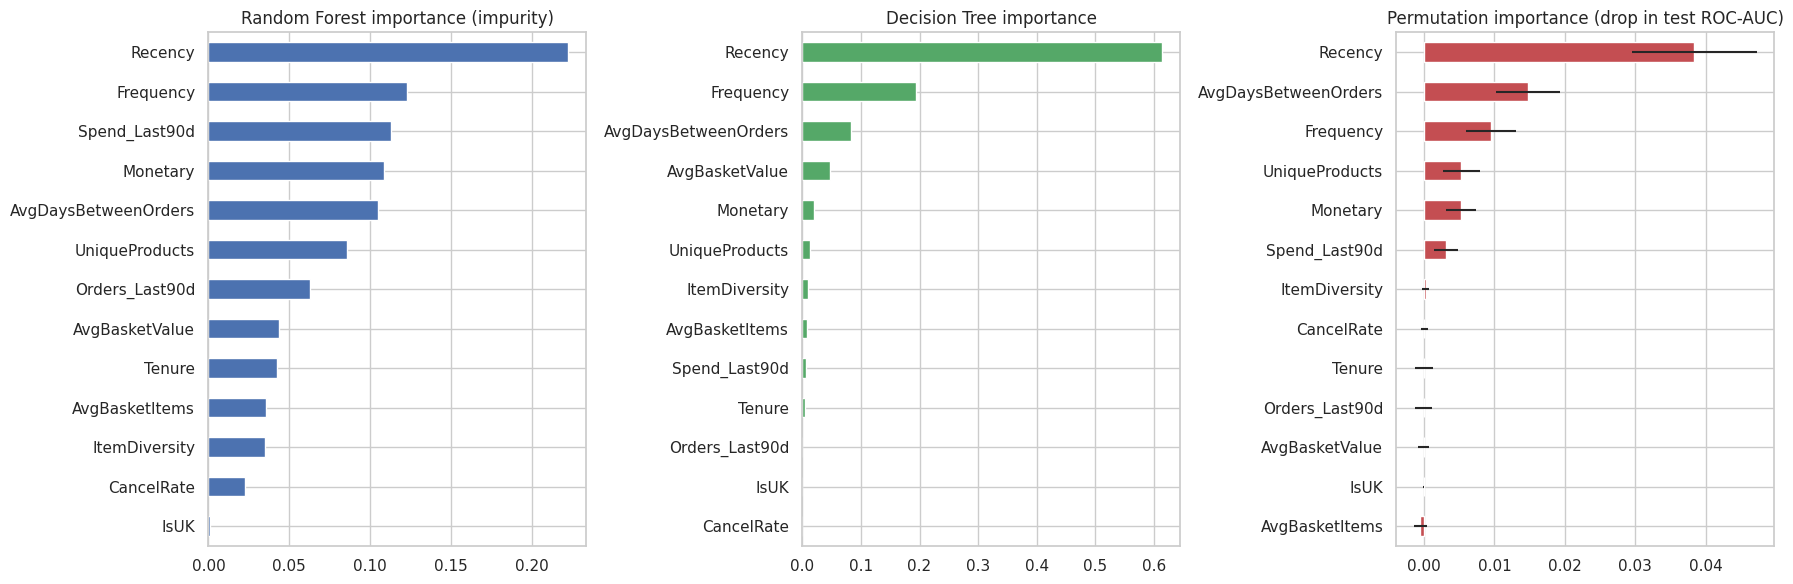

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
rf = imp["Random Forest"].sort_values()
rf.plot(kind="barh", color="#4C72B0", ax=axes[0]); axes[0].set_title("Random Forest importance (impurity)")
dt = imp["Decision Tree"].sort_values()
dt.plot(kind="barh", color="#55A868", ax=axes[1]); axes[1].set_title("Decision Tree importance")
pm = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
pm.plot(kind="barh", xerr=pd.Series(perm.importances_std, index=FEATURES).reindex(pm.index), color="#C44E52", ax=axes[2])
axes[2].set_title("Permutation importance (drop in test ROC-AUC)")
plt.tight_layout(); fig.savefig(OUT / "feature_importance.png", dpi=150); plt.show()

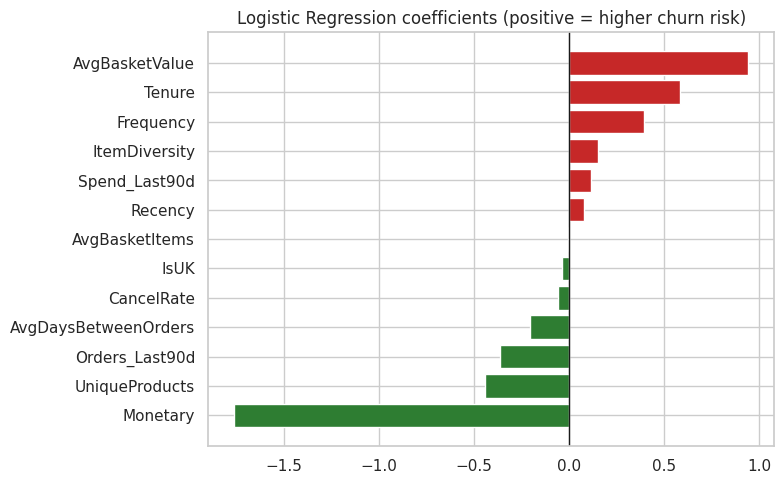

Monetary               -1.762
UniqueProducts         -0.443
Orders_Last90d         -0.360
AvgDaysBetweenOrders   -0.204
CancelRate             -0.059
IsUK                   -0.037
AvgBasketItems         -0.003
Recency                 0.079
Spend_Last90d           0.116
ItemDiversity           0.153
Frequency               0.395
Tenure                  0.586
AvgBasketValue          0.944
Name: LR coefficient, dtype: float64

In [14]:
# Direction of effect: Logistic Regression coefficients (features were log-transformed and standardized)
c = coef.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(c.index, c.values, color=["#2E7D32" if v < 0 else "#C62828" for v in c.values])
ax.axvline(0, color="k", lw=1)
ax.set_title("Logistic Regression coefficients (positive = higher churn risk)")
plt.tight_layout(); fig.savefig(OUT / "lr_coefficients.png", dpi=150); plt.show()
coef.round(3).sort_values()

In [15]:
# Decision rules of a shallow tree (easy to explain to non-technical staff)
from sklearn.tree import export_text, DecisionTreeClassifier as DTC
shallow = make_pipe(DTC(max_depth=3, min_samples_leaf=50, random_state=RS)).fit(X_train, y_train)
print(export_text(shallow.named_steps["model"], feature_names=FEATURES, max_depth=3))
print("Note: the thresholds above are in log-scaled, standardized units; use them for the ordering of splits, not as raw values.")

|--- Recency <= 0.09
|   |--- Frequency <= 0.59
|   |   |--- AvgDaysBetweenOrders <= 0.37
|   |   |   |--- class: 0
|   |   |--- AvgDaysBetweenOrders >  0.37
|   |   |   |--- class: 1
|   |--- Frequency >  0.59
|   |   |--- AvgDaysBetweenOrders <= -0.73
|   |   |   |--- class: 0
|   |   |--- AvgDaysBetweenOrders >  -0.73
|   |   |   |--- class: 0
|--- Recency >  0.09
|   |--- Recency <= 0.84
|   |   |--- Frequency <= -0.49
|   |   |   |--- class: 1
|   |   |--- Frequency >  -0.49
|   |   |   |--- class: 0
|   |--- Recency >  0.84
|   |   |--- AvgBasketValue <= -0.20
|   |   |   |--- class: 1
|   |   |--- AvgBasketValue >  -0.20
|   |   |   |--- class: 1

Note: the thresholds above are in log-scaled, standardized units; use them for the ordering of splits, not as raw values.


### Reading the feature importance
**Recency is the strongest predictor in every view.** It ranks first for the Decision Tree (61% of importance), the Random Forest (22%), XGBoost (29%) and permutation importance, where shuffling it lowers the test ROC-AUC by 0.038, about 2.6 times the next feature. Frequency and the average gap between orders come next, followed by recent spend (Spend_Last90d) and total Monetary.

**Direction of the effect (from the data, by quartile or group):**
- Churn rises steadily with Recency: 27% for customers whose last order was within 49 days, 85% for those more than 326 days ago.
- Customers with one order churn 80% of the time, versus 63% with 2 to 4 orders and 30% with 5 or more.
- Customers with no orders in the 90 days before the cut-off churn 71% of the time, versus 31% for those who ordered.
- Churn falls with total spend: 79% in the lowest spend quartile, 25% in the highest.

**Features that add almost nothing** once the others are present: IsUK, CancelRate, Tenure, AvgBasketItems (permutation importance close to zero). CancelRate is also confounded with customer size, because heavy buyers cancel more often.

**Caution on Logistic Regression coefficients.** Monetary, UniqueProducts and AvgBasketValue are correlated, so individual coefficients (for example Monetary at -1.76 and AvgBasketValue at +0.94) are unstable and should not be read one by one. Use the group rates above for direction and the permutation ranking for importance.

## 9. Churn risk tiers and business interpretation

In [16]:
scored = test[["CustomerID", "Recency", "Frequency", "Monetary", "Churn"]].copy()
scored["ChurnProb"] = probas[BEST]
scored["Risk"] = pd.cut(scored["ChurnProb"], [-0.01, 0.4, 0.7, 1.0], labels=["Low (<0.4)", "Medium (0.4-0.7)", "High (>=0.7)"])
q75 = X_train["Monetary"].quantile(0.75)               # value threshold from training data only
scored["Value"] = np.where(scored["Monetary"] >= q75, "High value", "Standard")

tier = (scored.groupby(["Risk", "Value"], observed=True)
        .agg(Customers=("CustomerID", "count"), Past_spend=("Monetary", "sum"), Actual_churn_rate=("Churn", "mean")).reset_index())
tier["Share_of_past_spend_%"] = tier["Past_spend"] / scored["Monetary"].sum() * 100
tier.round(2)

,Risk,Value,Customers,Past_spend,Actual_churn_rate,Share_of_past_spend_%
0,Low (<0.4),High value,221,2498066.46,0.15,77.28
1,Low (<0.4),Standard,142,155798.36,0.36,4.82
2,Medium (0.4-0.7),High value,30,168432.23,0.43,5.21
3,Medium (0.4-0.7),Standard,360,278456.97,0.68,8.61
4,High (>=0.7),High value,10,40258.58,0.90,1.25
5,High (>=0.7),Standard,294,91547.48,0.85,2.83


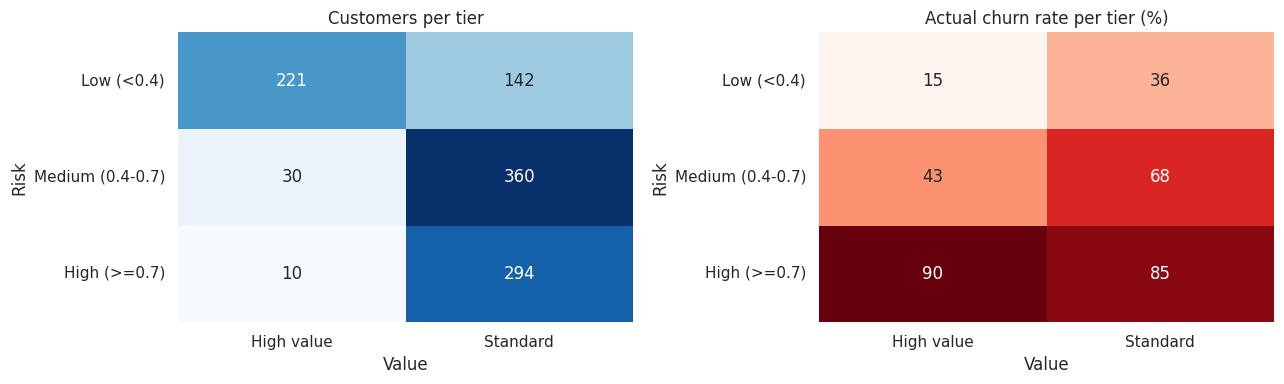

Priority group (high risk and high value): 10 customers, 1.2% of the test group's past spend, actual churn rate 90.0%


In [17]:
pivot = scored.pivot_table(index="Risk", columns="Value", values="Churn", aggfunc="mean", observed=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(scored.pivot_table(index="Risk", columns="Value", values="CustomerID", aggfunc="count", observed=True),
            annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0]); axes[0].set_title("Customers per tier")
sns.heatmap(pivot * 100, annot=True, fmt=".0f", cmap="Reds", cbar=False, ax=axes[1]); axes[1].set_title("Actual churn rate per tier (%)")
plt.tight_layout(); fig.savefig(OUT / "risk_tiers.png", dpi=150); plt.show()

priority = scored[(scored["Risk"] == "High (>=0.7)") & (scored["Value"] == "High value")]
print(f"Priority group (high risk and high value): {len(priority)} customers, "
      f"{priority['Monetary'].sum() / scored['Monetary'].sum():.1%} of the test group's past spend, "
      f"actual churn rate {priority['Churn'].mean():.1%}")

### Retention actions linked to the model
| Risk tier | Value | Action |
|---|---|---|
| High | High value | **Save first:** personal outreach or account call, tailored offer, check for service problems (for example cancellations) |
| High | Standard | Automated win-back email with a modest incentive; stop spending if there is no response |
| Medium | High value | Proactive reorder reminder or early access to new stock before the autumn peak |
| Medium or Low | Standard | Standard lifecycle emails; no discount (these customers are likely to order anyway) |

The expected effect of any campaign is not measured here and should be validated with an A/B test.

## 10. Save artifacts

In [18]:
joblib.dump({"models": {k: v.best_estimator_ for k, v in tuned.items()}, "features": FEATURES, "best": BEST}, OUT / "churn_models.pkl")
scored.to_csv(OUT / "test_churn_scores.csv", index=False)
tuning.assign(**{"Best parameters": tuning["Best parameters"].astype(str)}).to_csv(OUT / "tuning_results.csv")
ablation.round(4).to_csv(OUT / "smote_ablation.csv")
baseline.to_csv(OUT / "baseline_cv_auc.csv")
summary = {"best_model": BEST, "comparison": comparison.round(4).to_dict("index"),
           "best_params": {k: {a.replace("model__", ""): (None if b is None else (b if isinstance(b, (int, float, str)) else str(b)))
                               for a, b in v.best_params_.items()} for k, v in tuned.items()},
           "ablation": ablation.round(4).reset_index().to_dict("records"),
           "baseline": baseline["CV ROC-AUC"].to_dict(),
           "perm_importance": pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False).round(4).to_dict(),
           "rf_importance": imp["Random Forest"].sort_values(ascending=False).round(4).to_dict(),
           "dt_importance": imp["Decision Tree"].sort_values(ascending=False).round(4).to_dict(),
           "xgb_importance": imp["XGBoost (gain)"].sort_values(ascending=False).round(4).to_dict(),
           "lr_coef": coef.round(3).to_dict(),
           "tiers": tier.round(3).astype({"Risk": str}).to_dict("records"),
           "priority": {"customers": int(len(priority)), "share_past_spend": float(priority["Monetary"].sum() / scored["Monetary"].sum()),
                        "actual_churn": float(priority["Churn"].mean())},
           "confusion": {k: confusion_matrix(y_test, p).tolist() for k, p in preds.items()},
           "n_train": int(len(train)), "n_test": int(len(test)), "churn_rate": float(y_train.mean())}
(OUT / "churn_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['baseline_cv_auc.csv', 'churn_models.pkl', 'churn_summary.json', 'confusion_matrices.png', 'feature_importance.csv', 'feature_importance.png', 'lr_coefficients.png', 'model_comparison.csv', 'model_comparison.png', 'risk_tiers.png', 'roc_pr_curves.png', 'smote_ablation.csv', 'test_churn_scores.csv', 'tuning_results.csv']


## 11. Summary
- **Best model by cross-validated ROC-AUC:** Random Forest (CV 0.797). On the test set it reaches ROC-AUC 0.815, F1 0.781, Precision 0.789 and Recall 0.774.
- **The four tuned models are close:** test ROC-AUC is 0.815 (XGBoost), 0.815 (Random Forest), 0.811 (Logistic Regression) and 0.807 (Decision Tree). With 1,057 test customers a gap below 0.01 is within sampling noise, so a simple, explainable Logistic Regression is almost as good as the ensembles.
- **Tuning matters mostly for trees:** the default Decision Tree scored 0.631 CV ROC-AUC and the tuned one 0.778. The Logistic Regression default was already near its tuned score.
- **SMOTE:** it did not change ROC-AUC (differences of 0.002 or less). It raised Precision and lowered Recall; without SMOTE the F1-Score was slightly higher (Random Forest 0.802 versus 0.781). Churn is only 57% of customers, so oversampling is not needed here. It stays in the pipeline because the project requires imbalance handling, and the ablation documents the evidence.
- **Top features:** Recency, Frequency, and the average days between orders.
- **Business use:** 221 high-value customers have a low churn risk (about 15% actual churn) and hold 77% of past spend in the test group. Only 10 high-value customers are high-risk (90% actual churn) and 30 are medium-risk, so a personal retention effort is realistic for them. Most churners are standard-value customers, where cheap automated win-back is the right tool.